In [699]:
##### NOTES NOTES NOTES 
#drone(scen_12_cust_20Enhan2IFnewv5correct-2d)
#in this version used drone arrival and departure times for Scenario-4 (v5) 
#reached exactly the same solution with only t variables


In [700]:
#Importing the package numpy as np
import numpy as np
import pandas as pd
# "rnd" is an object that generate random numbers.
rnd = np.random
#set "seed(a number)"
rnd.seed(1000)
import copy

In [701]:
# Number of customers.
n = 12
c = 12
SL = 1
SR = 1
e = 20 #endurance
#RN = min([i for i in d1289 if i != 0])  #SINCE THE DRONE IS ON THE TRUCK
# Maximum capacity of the vehicle.
#Q = 20
#The set of nodes without the depot.
#C = [i for i in range(1,n+1)]  #represents the all customers
C = [i for i in range(1,n+1)]  #represents the all customers

#C = [1,2…………c]
N = [i for i in range(0,n+2)] # represents the set of all nodes in the network
#N = [0,1,2,……..c+1)] 
# V = [0]+ N
# A collection that contains the demand of each node.
#q = {i: rnd.randint(1,2) for i in N}


In [702]:
#G = [i for i in range(1,10)]  #represents the d
# updating G and using it in a different way to see the result
G = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

In [703]:
G1 = [4,5]

In [704]:
G2 = [1, 2, 3, 6, 7, 8, 9, 10, 11, 12]

In [705]:
N0 = [i for i in range(0,n+1)] 
#N0 = [0,1,2……………………c] represents the set of nodes from which a vehicle may depart

N1 = [i for i in range(1,n+2)] 
#N1 = [1,2……………………c+1] represents the set of nodes to which a vehicle may visit during the course of a tour
N0
N1

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

In [706]:
#C should go from 1 to n
#N should go from 0 to n+1
#N0 from 0 to n
#N1 from 1 to n+1
#A from i in N0 to j in N1
#D from i in N0 to j in C to k in N1
#You are defining small c and never using it.


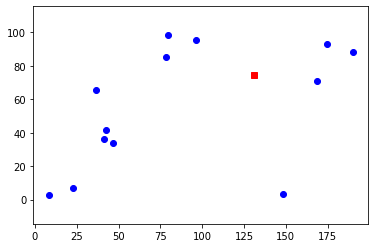

In [707]:
# Generating random numbers between (0 and 15) * 200.
loc_x = rnd.rand(len(N))*200
# Generating random numbers between (0 and 15) * 100.
loc_y = rnd.rand(len(N))*100
#Importing the package matplotlib.pyplot as plt.
import matplotlib.pyplot as plt
#Plotting the n nodes without the node 0 (depot) and chose the color blue for each node.
plt.scatter(loc_x[1:],loc_y[1:],c='b')
#for i in N:
    #plt.annotate('$q_%d=%d$'%(i,q[i]),(loc_x[i]+2,loc_y[i]))
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
plt.axis('equal');



In [708]:
loc_x

array([130.71791709,  23.00138862, 190.05657287,  96.43828029,
       174.49490704,  42.46653618,   8.14192495,  79.43889227,
        46.62643947, 168.34814485,  41.41646888, 148.49390672,
        78.43082556,  36.45130399])

In [709]:
loc_y

array([74.35394146,  6.9582081 , 88.53372044, 95.26443992, 93.11434347,
       41.5430953 ,  2.89816594, 98.20274846, 33.96376836, 70.66871939,
       36.18770676,  3.5105898 , 85.50582532, 65.72535081])

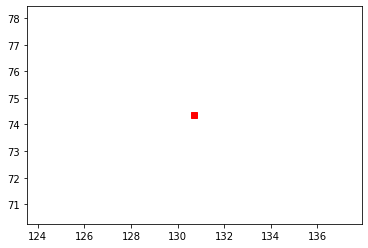

In [710]:
#Ploting the node 0, chosing the red like its color and the square form like a marker.
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
# additional
#plt.axis (‘equal’);


In [711]:
#Showing the Initial plot.
plt.show()


In [712]:
#Intializing the set of arcs A.
# A = [(i,j) for i in V for j in V if i!=j]
#08252020UPDATE A = [(i,j) for i in N for j in N if i!=j]
A = [(i,j) for i in N0 for j in N1 if i!=j]
#Defining and computing the distances which will be used as truck's travel time
#c= {(i,j):np.hypot(loc_x[i]-loc_x[j],loc_y[i]-loc_y[j]) for i,j in A}


In [713]:
#generating random uniform or creating random uniform
az =np.random.uniform(0, 10, size=(13,2))
az

array([[7.65682994, 5.54087238],
       [8.85092937, 9.04197615],
       [0.10421701, 0.74556736],
       [2.4462921 , 1.33304752],
       [6.979251  , 3.98204884],
       [8.83122191, 1.8100751 ],
       [4.32499172, 0.18143203],
       [6.91437862, 4.69690652],
       [1.2822219 , 8.91337051],
       [9.18203624, 0.73120994],
       [0.45447943, 4.38572896],
       [6.0172093 , 3.10227034],
       [6.81908242, 2.09013151]])

In [714]:
#final version for generation
ads = np.round(az,2).tolist()
ads.insert(13, ads[0])
ads, len(ads)
#ads=a.tolist()

([[7.66, 5.54],
  [8.85, 9.04],
  [0.1, 0.75],
  [2.45, 1.33],
  [6.98, 3.98],
  [8.83, 1.81],
  [4.32, 0.18],
  [6.91, 4.7],
  [1.28, 8.91],
  [9.18, 0.73],
  [0.45, 4.39],
  [6.02, 3.1],
  [6.82, 2.09],
  [7.66, 5.54]],
 14)

In [715]:
ads[11]

[6.02, 3.1]

In [716]:
#15-customer v10 scenario coordinates
#original first 12-customer data = data = [[5, 7], [7, 3], [8, 1], [1, 4], [4, 3], [1.2, 2.3], [3, 4.9], [0.5, 6.1], [0.8, 5.4], [2.7, 6.7], [3.8, 5.9], [1.8, 7.6], [2.3, 8.3], [5, 7]]
#original data = [[5, 7], [7, 3], [8, 1], [1, 4], [4, 3], [1.2, 2.3], [3, 4.9], [0.5, 6.1], [0.8, 5.4], [2.7, 6.7], [3.8, 5.9], [1.8, 7.6], [2.3, 8.3], [5, 7]]
#12-CUSTOMER data for the disruption at t= 15 when drone is between 4 and 2 and truck is between 4 and 5
#data = [[8, 5], [4, 6.5], [3.5, 7.5], [4.5, 9.5], [8, 9.5], [10.5, 8], [10, 6], [11, 4], [9, 3], [7, 2.5], [5, 1.5], [4, 3], [3.5,4.5], [8,5]]
data = ads
ctys = ['0', '1', '2','3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13']
df = pd.DataFrame(data, columns=['xcord', 'ycord'], index=ctys)
df

,xcord,ycord
0,7.66,5.54
1,8.85,9.04
2,0.10,0.75
3,2.45,1.33
4,6.98,3.98
5,8.83,1.81
6,4.32,0.18
7,6.91,4.70
8,1.28,8.91
9,9.18,0.73


In [717]:
import math
mnm = data
from collections import defaultdict
# initializing dict with lists
dronev2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue
        
        dronev2[(i, j)] = ((math.sqrt((mnm[i][0] - mnm[j][0])**2 + (mnm[i][1] - mnm[j][1])**2))*60)/35
        #dronev2[(i, j)] = 500
z2 = dronev2
z2
    

defaultdict(list,
            {(0, 1): 6.337318044725227,
             (0, 2): 15.342397439242456,
             (0, 3): 11.482925034456107,
             (0, 4): 2.9173093558193344,
             (0, 5): 6.7014759263789605,
             (0, 6): 10.826525249570699,
             (0, 7): 1.9304562218526984,
             (0, 8): 12.369174324480506,
             (0, 9): 8.64763268301841,
             (0, 10): 12.516234681893947,
             (0, 11): 5.039883380574984,
             (0, 12): 6.0870662482187665,
             (0, 13): 0.0,
             (1, 2): 20.66312420813504,
             (1, 3): 17.177459364064337,
             (1, 4): 9.247693590009016,
             (1, 5): 12.394333135653204,
             (1, 6): 17.058693396862587,
             (1, 7): 8.14947700838551,
             (1, 8): 12.979056284677107,
             (1, 9): 14.256942454932798,
             (1, 10): 16.459151663113982,
             (1, 11): 11.279491955558555,
             (1, 12): 12.412115213839769,
             (

In [718]:
mnm = data
from collections import defaultdict
# initializing dict with lists
truckv2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue        
        truckv2[(i, j)] = ((abs(mnm[i][0] - mnm[j][0])+ abs(mnm[i][1] - mnm[j][1]))*60)/25
z1 = truckv2
z1

defaultdict(list,
            {(0, 1): 11.255999999999997,
             (0, 2): 29.640000000000004,
             (0, 3): 22.608,
             (0, 4): 5.3759999999999994,
             (0, 5): 11.76,
             (0, 6): 20.88,
             (0, 7): 3.816,
             (0, 8): 23.4,
             (0, 9): 15.192,
             (0, 10): 20.064,
             (0, 11): 9.792,
             (0, 12): 10.296,
             (0, 13): 0.0,
             (1, 2): 40.896,
             (1, 3): 33.864,
             (1, 4): 16.631999999999994,
             (1, 5): 17.399999999999995,
             (1, 6): 32.135999999999996,
             (1, 7): 15.071999999999996,
             (1, 8): 18.479999999999997,
             (1, 9): 20.736,
             (1, 10): 31.32,
             (1, 11): 21.048,
             (1, 12): 21.552,
             (1, 13): 11.255999999999997,
             (2, 1): 40.896,
             (2, 3): 7.032,
             (2, 4): 24.264,
             (2, 5): 23.496000000000002,
             (2, 6): 11.

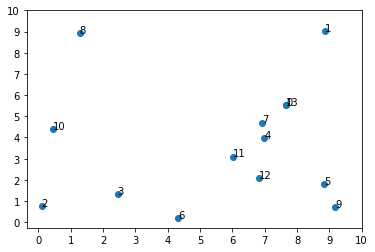

In [719]:
# drone(scen_15_cust_20-2IFdisratt15v5-2dROLLINGOLDOLDO-OLD OLD OLD OLD OLD OLD OLD )
data1 = data
#loc_x = [7, 4.5, 5, 4.5, 8, 10.5, 8.1, 11, 7, 5, 4, 3.5, 9 ]
x1=[]
y1= []
for i in range (len(data1)):
    #for j in range (2):
    x1.append(data1 [i][0])
    y1.append(data1 [i][1])

# Generating random numbers between (0 and 15) * 100.
#loc_y = rnd.rand(len(N))*100


#drone(scen_15_cust_20En2IF-v20disrt15vrolling) scenario nodes
import matplotlib.pyplot as plt

x = x1
y = y1

#n=['0', '1', '2','3', '4', '5', '6', '7', '8', '9' ]
numcity= ctys
fig, ax = plt.subplots()
ax.scatter(x, y)
#x1 = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,1,17,18,19,20]
#values = range(len(x1))
#plt.xticks([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20])
plt.xticks([0,1,2,3,4,5,6,7,8,9,10])
plt.yticks([0,1,2,3,4,5,6,7,8,9,10])
for i, txt in enumerate(numcity):
    ax.annotate(txt, (x [i], y [i]))

plt.show()

In [720]:
#Importing the docplex.mp.model from the CPLEX as Model
from docplex.mp.model import Model
mdl = Model('CVRP')

In [721]:
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE

In [722]:
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE

In [723]:
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE
###DELETE UP TO HERE

In [724]:
df.index = df.index.astype('int64')

In [725]:
##DETERMINING THE REGIONS - 5 REGIONS
MyReg2 = defaultdict(list)
for idx, *row in df.itertuples():
    if row[0] >= 0 and row[0] <= 3.33:
        MyReg2[1].append(idx)
    if row[0] > 3.33 and row[0] <= 6.67:
        MyReg2[2].append(idx)
    if row[0] > 6.67 and row[0] <= 10:
        MyReg2[3].append(idx)
MyReg2

defaultdict(list,
            {3: [0, 1, 4, 5, 7, 9, 12, 13], 1: [2, 3, 8, 10], 2: [6, 11]})

In [726]:
#stop5
#time constraint for rolls perfect info
#TConstraint2=[[15,25],[25,35],[35,45]]#DST15DISDUR30
#TConstraint2=[[15,35],[35,55],[55,75]]#DST15DISDUR60
TConstraint2=[[30,40],[40,50],[50,60]]#DST30DISDUR30
#TConstraint2=[[30,50],[50,70],[70,90]]#DST30DISDUR60

In [727]:
#this is extra
#transforming the data frame into list of lists
data = df.values.tolist()
B = data
B

[[7.66, 5.54],
 [8.85, 9.04],
 [0.1, 0.75],
 [2.45, 1.33],
 [6.98, 3.98],
 [8.83, 1.81],
 [4.32, 0.18],
 [6.91, 4.7],
 [1.28, 8.91],
 [9.18, 0.73],
 [0.45, 4.39],
 [6.02, 3.1],
 [6.82, 2.09],
 [7.66, 5.54]]

In [728]:
#stop1 stop1 stop1 

In [729]:
import math
mnm = data
from collections import defaultdict
# initializing dict with lists
dronev2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue
        
        dronev2[(i, j)] = ((math.sqrt((mnm[i][0] - mnm[j][0])**2 + (mnm[i][1] - mnm[j][1])**2))*60)/35
        #dronev2[(i, j)] = 200
        
z2 = dronev2
z2

defaultdict(list,
            {(0, 1): 6.337318044725227,
             (0, 2): 15.342397439242456,
             (0, 3): 11.482925034456107,
             (0, 4): 2.9173093558193344,
             (0, 5): 6.7014759263789605,
             (0, 6): 10.826525249570699,
             (0, 7): 1.9304562218526984,
             (0, 8): 12.369174324480506,
             (0, 9): 8.64763268301841,
             (0, 10): 12.516234681893947,
             (0, 11): 5.039883380574984,
             (0, 12): 6.0870662482187665,
             (0, 13): 0.0,
             (1, 2): 20.66312420813504,
             (1, 3): 17.177459364064337,
             (1, 4): 9.247693590009016,
             (1, 5): 12.394333135653204,
             (1, 6): 17.058693396862587,
             (1, 7): 8.14947700838551,
             (1, 8): 12.979056284677107,
             (1, 9): 14.256942454932798,
             (1, 10): 16.459151663113982,
             (1, 11): 11.279491955558555,
             (1, 12): 12.412115213839769,
             (

In [730]:
mnm = data
from collections import defaultdict
# initializing dict with lists
truckv2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue        
        truckv2[(i, j)] = ((abs(mnm[i][0] - mnm[j][0])+ abs(mnm[i][1] - mnm[j][1]))*60)/25
z1 = truckv2
z1

defaultdict(list,
            {(0, 1): 11.255999999999997,
             (0, 2): 29.640000000000004,
             (0, 3): 22.608,
             (0, 4): 5.3759999999999994,
             (0, 5): 11.76,
             (0, 6): 20.88,
             (0, 7): 3.816,
             (0, 8): 23.4,
             (0, 9): 15.192,
             (0, 10): 20.064,
             (0, 11): 9.792,
             (0, 12): 10.296,
             (0, 13): 0.0,
             (1, 2): 40.896,
             (1, 3): 33.864,
             (1, 4): 16.631999999999994,
             (1, 5): 17.399999999999995,
             (1, 6): 32.135999999999996,
             (1, 7): 15.071999999999996,
             (1, 8): 18.479999999999997,
             (1, 9): 20.736,
             (1, 10): 31.32,
             (1, 11): 21.048,
             (1, 12): 21.552,
             (1, 13): 11.255999999999997,
             (2, 1): 40.896,
             (2, 3): 7.032,
             (2, 4): 24.264,
             (2, 5): 23.496000000000002,
             (2, 6): 11.

In [731]:
#stopb

In [732]:
#Importing the docplex.mp.model from the CPLEX as Model
from docplex.mp.model import Model
mdl = Model('CVRP')

In [733]:
#Initializing our binary variable x_i,j if the truck travels from node i to node j
x=mdl.binary_var_dict (A,name='x')
#Initializing our cumulative demand u
# IN 11 COMMENT ONLY u=mdl.continuous_var_dict (N,ub=Q ,name = 'u')

In [734]:
#drone launch and serve binary variable 
g=mdl.binary_var_dict (A,name='g')

In [735]:
#drone rendezvous and serve binary variable 
h=mdl.binary_var_dict (A,name='h')

In [736]:
#w definition as a list like t and d (second trial)
w=mdl.continuous_var_list (n+2, ub=1000 , lb =0, name = 'w') #3IF

In [737]:
#3IF z instead of z, v is used
v=mdl.binary_var_dict (N,name='v')

In [738]:
#drone collection or retrieval binary variable 
m = mdl.binary_var_dict (N,name='m')

In [739]:
# drone launch binary variable 
m2 = mdl.binary_var_dict (N,name='m2')

In [740]:
# drone launch binary variable 
r = mdl.binary_var_dict (N,name='r')

In [741]:
# drone launch binary variable 
binv1 = mdl.binary_var_dict (N,name='binv1')

In [742]:
# drone launch binary variable 
binv2 = mdl.binary_var_dict (N,name='binv2')

In [743]:
# drone launch binary variable 
binv3 = mdl.binary_var_dict (N,name='binv3')

In [744]:
# drone launch binary variable 
binv4 = mdl.binary_var_dict (N,name='binv4')

In [745]:
# drone launch binary variable 
binv5 = mdl.binary_var_dict (N,name='binv5')

In [746]:
# drone launch binary variable 
binv6 = mdl.binary_var_dict (N,name='binv6')

In [747]:
# drone launch binary variable 
binv7 = mdl.binary_var_dict (N,name='binv7')

In [748]:
# drone launch binary variable 
binv8 = mdl.binary_var_dict (N,name='binv8')

In [749]:
# drone launch binary variable 
binv9 = mdl.binary_var_dict (N,name='binv9')

In [750]:
# drone launch binary variable 
binv10 = mdl.binary_var_dict (N,name='binv10')

In [751]:
#t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF

In [752]:
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12

docplex.mp.LinearConstraint[ac3IF](t_0,EQ,0)

In [753]:
d = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [754]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d[0] == 0, ctname = 'dddef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddef2IF](d_0,EQ,0)

In [755]:
d1 = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd1') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [756]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d1[0] == 0, ctname = 'dddEPef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddEPef2IF](d1_0,EQ,0)

In [757]:
mdl.add_constraints(((mdl.sum(h[i,j] for i in G2 if i != j) == m[j] ) for j in N1 if j != 0  ), names = 'cDR2IF28d92IF1')

[docplex.mp.LinearConstraint[cDR2IF28d92IF11](h_2_1+h_3_1+h_6_1+h_7_1+h_8_1+h_9_1+h_10_1+h_11_1+h_12_1,EQ,m_1),
 docplex.mp.LinearConstraint[cDR2IF28d92IF12](h_1_2+h_3_2+h_6_2+h_7_2+h_8_2+h_9_2+h_10_2+h_11_2+h_12_2,EQ,m_2),
 docplex.mp.LinearConstraint[cDR2IF28d92IF13](h_1_3+h_2_3+h_6_3+h_7_3+h_8_3+h_9_3+h_10_3+h_11_3+h_12_3,EQ,m_3),
 docplex.mp.LinearConstraint[cDR2IF28d92IF14](h_1_4+h_2_4+h_3_4+h_6_4+h_7_4+h_8_4+h_9_4+h_10_4+h_11_4+h_12_4,EQ,m_4),
 docplex.mp.LinearConstraint[cDR2IF28d92IF15](h_1_5+h_2_5+h_3_5+h_6_5+h_7_5+h_8_5+h_9_5+h_10_5+h_11_5+h_12_5,EQ,m_5),
 docplex.mp.LinearConstraint[cDR2IF28d92IF16](h_1_6+h_2_6+h_3_6+h_7_6+h_8_6+h_9_6+h_10_6+h_11_6+h_12_6,EQ,m_6),
 docplex.mp.LinearConstraint[cDR2IF28d92IF17](h_1_7+h_2_7+h_3_7+h_6_7+h_8_7+h_9_7+h_10_7+h_11_7+h_12_7,EQ,m_7),
 docplex.mp.LinearConstraint[cDR2IF28d92IF18](h_1_8+h_2_8+h_3_8+h_6_8+h_7_8+h_9_8+h_10_8+h_11_8+h_12_8,EQ,m_8),
 docplex.mp.LinearConstraint[cDR2IF28d92IF19](h_1_9+h_2_9+h_3_9+h_6_9+h_7_9+h_8_9+h_10_9+h_1

In [758]:
#ORIGINAL mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 ), names = 'cDR3IF28d92IF')
mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 if i != n+1), names = 'cDR3IF28d92IF')

[docplex.mp.LinearConstraint[cDR3IF28d92IF1](g_1_2+g_1_3+g_1_4+g_1_5+g_1_6+g_1_7+g_1_8+g_1_9+g_1_10+g_1_11+g_1_12+g_1_13,EQ,m2_1),
 docplex.mp.LinearConstraint[cDR3IF28d92IF2](g_2_1+g_2_3+g_2_4+g_2_5+g_2_6+g_2_7+g_2_8+g_2_9+g_2_10+g_2_11+g_2_12+g_2_13,EQ,m2_2),
 docplex.mp.LinearConstraint[cDR3IF28d92IF3](g_3_1+g_3_2+g_3_4+g_3_5+g_3_6+g_3_7+g_3_8+g_3_9+g_3_10+g_3_11+g_3_12+g_3_13,EQ,m2_3),
 docplex.mp.LinearConstraint[cDR3IF28d92IF4](g_4_1+g_4_2+g_4_3+g_4_5+g_4_6+g_4_7+g_4_8+g_4_9+g_4_10+g_4_11+g_4_12+g_4_13,EQ,m2_4),
 docplex.mp.LinearConstraint[cDR3IF28d92IF5](g_5_1+g_5_2+g_5_3+g_5_4+g_5_6+g_5_7+g_5_8+g_5_9+g_5_10+g_5_11+g_5_12+g_5_13,EQ,m2_5),
 docplex.mp.LinearConstraint[cDR3IF28d92IF6](g_6_1+g_6_2+g_6_3+g_6_4+g_6_5+g_6_7+g_6_8+g_6_9+g_6_10+g_6_11+g_6_12+g_6_13,EQ,m2_6),
 docplex.mp.LinearConstraint[cDR3IF28d92IF7](g_7_1+g_7_2+g_7_3+g_7_4+g_7_5+g_7_6+g_7_8+g_7_9+g_7_10+g_7_11+g_7_12+g_7_13,EQ,m2_7),
 docplex.mp.LinearConstraint[cDR3IF28d92IF8](g_8_1+g_8_2+g_8_3+g_8_4+g_8_5+g_8_6+g_

In [759]:
mdl.add_constraint(m2[n+1] == 0, ctname = 'dddN13ef2IF') #ADDITIONAL m2 constraint node 13 will never be launch point

docplex.mp.LinearConstraint[dddN13ef2IF](m2_13,EQ,0)

In [760]:
#3-IF Constraint 3 part:1 (SAME FOR THE 2-IF)
#truck departs from the depot exactly once (Constraint 3)(CM)
#Dr.Silva last update mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 
#WORKS TOO-3 mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 for j in N)
# WORKS LAST mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#08252020(v23-270)mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0)== 1 for j in N1)
#RECENT MOST UPDATE modified as follow mdl.add_constraints(mdl.sum(x[0,j] for j in N1)== 1)
#mdl.add_constraint(mdl.sum(x[0,j] for j in N1)== 1, ctname = 'b')
#3-IF original mdl.add_constraint(mdl.sum(x[0,j] for j in N1 )== 1, ctname = 'b3IF')
mdl.add_constraint((mdl.sum(x[0,j] for j in N1 if j != n+1 )== 1), ctname = 'b3IF')


docplex.mp.LinearConstraint[b3IF](x_0_1+x_0_2+x_0_3+x_0_4+x_0_5+x_0_6+x_0_7+x_0_8+x_0_9+x_0_10+x_0_11+x_0_12,EQ,1)

In [761]:
#ADDITIONAL-1 
mdl.add_constraint((mdl.sum(x[0,n+1]  )== 0), ctname = 'bAD3IF')

docplex.mp.LinearConstraint[bAD3IF](x_0_13,EQ,0)

In [762]:
#ADDITIONAL-2
#mdl.add_constraint(((g[i,j] for (i,j) in A if (i, j) == (i, 4) if (i,j) == (i,5))  == 0 ), ctname = 'bAD2dr2IF')
mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G1 if i != j ), names = 'myD2dr2IF')
#mdl.add_constraints((y[i,j,k] == 0 for i in N0 for k in N1 for j in G1 if i != j if i != k if j != k) , names='gg')

[docplex.mp.LinearConstraint[myD2dr2IF1](g_0_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF2](g_0_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF3](g_1_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF4](g_1_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF5](g_2_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF6](g_2_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF7](g_3_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF8](g_3_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF9](g_4_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF10](g_5_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF11](g_6_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF12](g_6_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF13](g_7_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF14](g_7_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF15](g_8_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF16](g_8_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF17](g_9_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF18](g_9_5,EQ,0),
 docplex.mp.LinearC

In [763]:
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES stop100 phase2
#mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G2 if i != j ), names = 'myD2dr2IFN1')
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES

In [764]:
#3-IF Constraint 3 part:2 (SAME FOR THE 2-IF )
#truck returns the depot exactly once (Constraint 4)(altered a bit)
#mdl.add_constraints(mdl.sum(x[0,i])for i in range N) ==1)
#mdl.add_constraints(mdl.sum(x[j,0] for j in range (n+1) if j!=0)==1 for j in N)
# WORKS TOO mdl.add_constraints((mdl.sum(x[j,0] for j in range (n+1) if j!=0)) ==1 for j in N)
# WORKS previous (mdl.add_constraints(mdl.sum(x[j,0])  == 1)for j in range (n+1) if j!=0)
#WORKS PREVIOUS mdl.add_constraints(mdl.sum(x[j,0] for j in N if j != 0 )  == 1 for j in N if j!=0)
# WORKS LAST mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)  == 1 for j in N if j!=0)
#mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)== 1 for j in N)
# WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1 for j in N0)
#mdl.add_constraints((mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1) for j in N0)
#08252020(v23-271)mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11)== 1 for i in N0)
# (MOST RECENT UPDATE modified below) mdl.add_constraints(mdl.sum(x[i,11] for i in N0)== 1)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1 for i in N0)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1)
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0)== 1, ctname = 'c')
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0 if i != 0)== 1, ctname = 'c3IF')
mdl.add_constraint((mdl.sum(x[i,n+1] for i in N0 if i != 0) == 1), ctname = 'c3IF')

docplex.mp.LinearConstraint[c3IF](x_1_13+x_2_13+x_3_13+x_4_13+x_5_13+x_6_13+x_7_13+x_8_13+x_9_13+x_10_13+x_11_13+x_12_13,EQ,1)

In [765]:
#3-IF Constraint 4 (a bit similar to CM Const6 but different) (SAME FOR THE 2-IF)
#truck flow conservation constraint
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,k] for k in N1 if j!=k) for j in C), names = 'e') #CM -6
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] ) for j in C), names = 'e3IF') # working
#mdl.add_constraints((mdl.sum(x[i,j] for i in A if i!=j) == mdl.sum(x[j,i] for i in A if i!=j ) for j in C ), names = 'e3IF') #3IF normal but not working
#WORKING PREVIOUSLY mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] for i in N1 if i!=j) for j in C), names = 'e3IF') # working but not original 3IF
#MOST RECENT mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) == mdl.sum(x[j,i] for i in N1 if i != j ) for j in C ), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[e3IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1,EQ,x_1_2+x_1_3+x_1_4+x_1_5+x_1_6+x_1_7+x_1_8+x_1_9+x_1_10+x_1_11+x_1_12+x_1_13),
 docplex.mp.LinearConstraint[e3IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2,EQ,x_2_1+x_2_3+x_2_4+x_2_5+x_2_6+x_2_7+x_2_8+x_2_9+x_2_10+x_2_11+x_2_12+x_2_13),
 docplex.mp.LinearConstraint[e3IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3,EQ,x_3_1+x_3_2+x_3_4+x_3_5+x_3_6+x_3_7+x_3_8+x_3_9+x_3_10+x_3_11+x_3_12+x_3_13),
 docplex.mp.LinearConstraint[e3IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4,EQ,x_4_1+x_4_2+x_4_3+x_4_5+x_4_6+x_4_7+x_4_8+x_4_9+x_4_10+x_4_11+x_4_12+x_4_13),
 docplex.mp.LinearConstraint[e3IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5,EQ,x_5_1+x_5_2+x_5_3+x_5_4+x_5_6+x_5_7+x_5_8+x_5_9+x_5_10+x_5_11+x_5_12+x_5_13),
 docplex.mp.LinearConstraint[e3IF6](x_0_

In [766]:
#Constraint-5 3IF (SAME FOR THE 2-IF)
#CM-constraint 19 was used to generate this constraint
#works too mdl.add_constraints(((t[j]  - t[i]  >= z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
#WORKING TOO mdl.add_constraints(((t[j]  >= t[i] +z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
##ORIGINAL mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials
mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] + m2[j] + m[j]- 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials

[docplex.mp.LinearConstraint[ap3IF1](t_1,GE,10000x_0_1+m_1+m2_1+t_0-9988.744),
 docplex.mp.LinearConstraint[ap3IF2](t_2,GE,10000x_0_2+m_2+m2_2+t_0-9970.360),
 docplex.mp.LinearConstraint[ap3IF3](t_3,GE,10000x_0_3+m_3+m2_3+t_0-9977.392),
 docplex.mp.LinearConstraint[ap3IF4](t_4,GE,10000x_0_4+m_4+m2_4+t_0-9994.624),
 docplex.mp.LinearConstraint[ap3IF5](t_5,GE,10000x_0_5+m_5+m2_5+t_0-9988.240),
 docplex.mp.LinearConstraint[ap3IF6](t_6,GE,10000x_0_6+m_6+m2_6+t_0-9979.120),
 docplex.mp.LinearConstraint[ap3IF7](t_7,GE,10000x_0_7+m_7+m2_7+t_0-9996.184),
 docplex.mp.LinearConstraint[ap3IF8](t_8,GE,10000x_0_8+m_8+m2_8+t_0-9976.600),
 docplex.mp.LinearConstraint[ap3IF9](t_9,GE,10000x_0_9+m_9+m2_9+t_0-9984.808),
 docplex.mp.LinearConstraint[ap3IF10](t_10,GE,10000x_0_10+m_10+m2_10+t_0-9979.936),
 docplex.mp.LinearConstraint[ap3IF11](t_11,GE,10000x_0_11+m_11+m2_11+t_0-9990.208),
 docplex.mp.LinearConstraint[ap3IF12](t_12,GE,10000x_0_12+m_12+m2_12+t_0-9989.704),
 docplex.mp.LinearConstraint[ap3IF13]

In [767]:
#########ROLL DISRUPTION CONSTRAINTS FIRST TRIAL asli1 asli1 asli1 
#Constraint-5 3IF (SAME FOR THE 2-IF)
#CM-constraint 19 was used to generate this constraint
#works too mdl.add_constraints(((t[j]  - t[i]  >= z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
#WORKING TOO mdl.add_constraints(((t[j]  >= t[i] +z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
##ORIGINAL mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials
##mdl.add_constraints(((t[i]  <= TConstraint2[2][0] + 1000*(1- g[i,j])) for (i,j) in A if j != 0 if i in MyReg2[3] ), names = 'newroll1cnt')#CONSTR 5 trials

In [768]:
##mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if j in MyReg2[3])
###mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if j in MyReg2[3])

In [769]:
#constraint-7 (SAME FOR THE 2-IF )(3IF)if drone arrive at a node after the truck, truck must wait that is imposed by this constraint
#mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j ), names = 'd73IF')
#WORKING mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j), names = 'd73IF')
mdl.add_constraints((w[j] >= t[j] - t[i] - m2[j]- m[j] - z1[i,j] - 10000*(1- x[i,j])  for (i,j) in A ), names = 'd73IF')

[docplex.mp.LinearConstraint[d73IF1](w_1,GE,10000x_0_1-m_1-m2_1-t_0+t_1-10011.256),
 docplex.mp.LinearConstraint[d73IF2](w_2,GE,10000x_0_2-m_2-m2_2-t_0+t_2-10029.640),
 docplex.mp.LinearConstraint[d73IF3](w_3,GE,10000x_0_3-m_3-m2_3-t_0+t_3-10022.608),
 docplex.mp.LinearConstraint[d73IF4](w_4,GE,10000x_0_4-m_4-m2_4-t_0+t_4-10005.376),
 docplex.mp.LinearConstraint[d73IF5](w_5,GE,10000x_0_5-m_5-m2_5-t_0+t_5-10011.760),
 docplex.mp.LinearConstraint[d73IF6](w_6,GE,10000x_0_6-m_6-m2_6-t_0+t_6-10020.880),
 docplex.mp.LinearConstraint[d73IF7](w_7,GE,10000x_0_7-m_7-m2_7-t_0+t_7-10003.816),
 docplex.mp.LinearConstraint[d73IF8](w_8,GE,10000x_0_8-m_8-m2_8-t_0+t_8-10023.400),
 docplex.mp.LinearConstraint[d73IF9](w_9,GE,10000x_0_9-m_9-m2_9-t_0+t_9-10015.192),
 docplex.mp.LinearConstraint[d73IF10](w_10,GE,10000x_0_10-m_10-m2_10-t_0+t_10-10020.064),
 docplex.mp.LinearConstraint[d73IF11](w_11,GE,10000x_0_11-m_11-m2_11-t_0+t_11-10009.792),
 docplex.mp.LinearConstraint[d73IF12](w_12,GE,10000x_0_12-m_12-m

In [770]:
#constraint-9 (3IF)drone battery endurance constraints (SAME FOR THE 2-IF)
#WORKING mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for i in N0 if i!=j)for j in C ), names = 'd93IF')
#LAST VERSION OF THE 3-IF mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for j in C if i!=j)for i in N1 if i != 11 ), names = 'd93IF')
#FIRST VERSION mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if i!=j if j != 11) for i in N1 ), names = 'd92IF')
#mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if i!=j if j != 11) for i in N1 ), names = 'd92IF')#SECOND VERSION
#MOST RECENT mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if j != 11) for i in N1 ), names = 'd92IF')
mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if j != n+1 if i != j) for i in N1 ), names = 'd92IF')

[docplex.mp.LinearConstraint[d92IF1](v_1,LE,x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1),
 docplex.mp.LinearConstraint[d92IF2](v_2,LE,x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2),
 docplex.mp.LinearConstraint[d92IF3](v_3,LE,x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3),
 docplex.mp.LinearConstraint[d92IF4](v_4,LE,x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4),
 docplex.mp.LinearConstraint[d92IF5](v_5,LE,x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5),
 docplex.mp.LinearConstraint[d92IF6](v_6,LE,x_0_6+x_1_6+x_2_6+x_3_6+x_4_6+x_5_6+x_7_6+x_8_6+x_9_6+x_10_6+x_11_6+x_12_6),
 docplex.mp.LinearConstraint[d92IF7](v_7,LE,x_0_7+x_1_7+x_2_7+x_3_7+x_4_7+x_5_7+x_6_7+x_8_7+x_9_7+x_10_7+x_11_7+x_12_7),
 docplex.mp.LinearConstraint[d92IF8](v_8,LE,x_0_8+x_1_8+x_2_8+x_3_8+x_4_8+x_5_8+x_6_8+x_7_8+x_9_8+x_10_8+x_11_8+x_12_8),
 docplex.mp.LinearConstraint[d92

In [771]:
#Constraint_23 (2-IF)
#mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A) + mdl.sum(g[i,j] for (i,j) in A ) == 1 for j in C ), names = 'd23n2IF')
#MOST RECENT WORKING ONE mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')
#mdl.add_constraints(((mdl.sum(x[i,j]) + mdl.sum(g[i,j]) == 1 )for i, in N0 for j in N1 if i != j), names = 'd23n2IF')
#WORKING  VERSION mdl.add_constraints(((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 ) for j in C ), names = 'd23n2IF')
#mdl.add_constraints((mdl.sum(x[i,j])  + mdl.sum(g[i,j] ) for (i,j) in A) == 1 for j in C ), names = 'd23n2IF')
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')


[docplex.mp.LinearConstraint[d23n2IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1+g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2+g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3+g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4+g_0_4+g_1_4+g_2_4+g_3_4+g_5_4+g_6_4+g_7_4+g_8_4+g_9_4+g_10_4+g_11_4+g_12_4,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5+g_0_5+g_1_5+g_2_5+g_3_5+g_4_5+g_6_5+g_7_5+g_8_5+g_9_5+g_10_5+g_11_5+g_12_5,EQ,1),
 docplex.mp.LinearCo

In [772]:
#Constarint 24
mdl.add_constraints(((t[j]  >= t[i] + z2[i,j] - 10000*(1- g[i,j])) for (i,j) in A ), names = 'C24ap2IF')

[docplex.mp.LinearConstraint[C24ap2IF1](t_1,GE,10000g_0_1+t_0-9993.663),
 docplex.mp.LinearConstraint[C24ap2IF2](t_2,GE,10000g_0_2+t_0-9984.658),
 docplex.mp.LinearConstraint[C24ap2IF3](t_3,GE,10000g_0_3+t_0-9988.517),
 docplex.mp.LinearConstraint[C24ap2IF4](t_4,GE,10000g_0_4+t_0-9997.083),
 docplex.mp.LinearConstraint[C24ap2IF5](t_5,GE,10000g_0_5+t_0-9993.299),
 docplex.mp.LinearConstraint[C24ap2IF6](t_6,GE,10000g_0_6+t_0-9989.173),
 docplex.mp.LinearConstraint[C24ap2IF7](t_7,GE,10000g_0_7+t_0-9998.070),
 docplex.mp.LinearConstraint[C24ap2IF8](t_8,GE,10000g_0_8+t_0-9987.631),
 docplex.mp.LinearConstraint[C24ap2IF9](t_9,GE,10000g_0_9+t_0-9991.352),
 docplex.mp.LinearConstraint[C24ap2IF10](t_10,GE,10000g_0_10+t_0-9987.484),
 docplex.mp.LinearConstraint[C24ap2IF11](t_11,GE,10000g_0_11+t_0-9994.960),
 docplex.mp.LinearConstraint[C24ap2IF12](t_12,GE,10000g_0_12+t_0-9993.913),
 docplex.mp.LinearConstraint[C24ap2IF13](t_13,GE,10000g_0_13+t_0-10000),
 docplex.mp.LinearConstraint[C24ap2IF14](t

In [773]:
#Constarint 25
# DEACTIVATED mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')
#Constarint 25 (UPDATED FOR DEFINING DRONE ARRIVAL TIME)
mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] + m2[k] + m[k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')

[docplex.mp.LinearConstraint[C25ap2IF1](t_1,GE,10000h_0_1+m_1+m2_1+t_0-9993.663),
 docplex.mp.LinearConstraint[C25ap2IF2](t_2,GE,10000h_0_2+m_2+m2_2+t_0-9984.658),
 docplex.mp.LinearConstraint[C25ap2IF3](t_3,GE,10000h_0_3+m_3+m2_3+t_0-9988.517),
 docplex.mp.LinearConstraint[C25ap2IF4](t_4,GE,10000h_0_4+m_4+m2_4+t_0-9997.083),
 docplex.mp.LinearConstraint[C25ap2IF5](t_5,GE,10000h_0_5+m_5+m2_5+t_0-9993.299),
 docplex.mp.LinearConstraint[C25ap2IF6](t_6,GE,10000h_0_6+m_6+m2_6+t_0-9989.173),
 docplex.mp.LinearConstraint[C25ap2IF7](t_7,GE,10000h_0_7+m_7+m2_7+t_0-9998.070),
 docplex.mp.LinearConstraint[C25ap2IF8](t_8,GE,10000h_0_8+m_8+m2_8+t_0-9987.631),
 docplex.mp.LinearConstraint[C25ap2IF9](t_9,GE,10000h_0_9+m_9+m2_9+t_0-9991.352),
 docplex.mp.LinearConstraint[C25ap2IF10](t_10,GE,10000h_0_10+m_10+m2_10+t_0-9987.484),
 docplex.mp.LinearConstraint[C25ap2IF11](t_11,GE,10000h_0_11+m_11+m2_11+t_0-9994.960),
 docplex.mp.LinearConstraint[C25ap2IF12](t_12,GE,10000h_0_12+m_12+m2_12+t_0-9993.913),
 

In [774]:
#Constarint 26
#RELAXED VERSION CONSTR. 33 INCLUDED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED
#DEACTIVATED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED 
mdl.add_constraints(((t[k] -  t[i] - m2[k] - 10000*(2- g[i,j] - h[j,k] )  <= e) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') #updated to represent departure times

[docplex.mp.LinearConstraint[C26ap2IF1](10000g_0_1+10000h_1_2-m2_2-t_0+t_2-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF2](10000g_0_1+10000h_1_3-m2_3-t_0+t_3-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF3](10000g_0_1+10000h_1_4-m2_4-t_0+t_4-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF4](10000g_0_1+10000h_1_5-m2_5-t_0+t_5-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF5](10000g_0_1+10000h_1_6-m2_6-t_0+t_6-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF6](10000g_0_1+10000h_1_7-m2_7-t_0+t_7-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF7](10000g_0_1+10000h_1_8-m2_8-t_0+t_8-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF8](10000g_0_1+10000h_1_9-m2_9-t_0+t_9-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF9](10000g_0_1+10000h_1_10-m2_10-t_0+t_10-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF10](10000g_0_1+10000h_1_11-m2_11-t_0+t_11-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF11](10000g_0_1+10000h_1_12-m2_12-t_0+t_12-20000,LE,20),
 docplex.m

In [775]:
#Constraint_27 (2-IF)
mdl.add_constraints((mdl.sum(g[i,j] for i in N0 if i != j) == mdl.sum(h[j,k] for k in N1 if j != k) for j in G2 ), names = 'c27d92IF')

[docplex.mp.LinearConstraint[c27d92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,EQ,h_1_2+h_1_3+h_1_4+h_1_5+h_1_6+h_1_7+h_1_8+h_1_9+h_1_10+h_1_11+h_1_12+h_1_13),
 docplex.mp.LinearConstraint[c27d92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,EQ,h_2_1+h_2_3+h_2_4+h_2_5+h_2_6+h_2_7+h_2_8+h_2_9+h_2_10+h_2_11+h_2_12+h_2_13),
 docplex.mp.LinearConstraint[c27d92IF3](g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,EQ,h_3_1+h_3_2+h_3_4+h_3_5+h_3_6+h_3_7+h_3_8+h_3_9+h_3_10+h_3_11+h_3_12+h_3_13),
 docplex.mp.LinearConstraint[c27d92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6+g_10_6+g_11_6+g_12_6,EQ,h_6_1+h_6_2+h_6_3+h_6_4+h_6_5+h_6_7+h_6_8+h_6_9+h_6_10+h_6_11+h_6_12+h_6_13),
 docplex.mp.LinearConstraint[c27d92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7+g_10_7+g_11_7+g_12_7,EQ,h_7_1+h_7_2+h_7_3+h_7_4+h_7_5+h_7_6+h_7_8+h_7_9+h_7_10+h_7_11+h_7_12+h_7_13),
 docplex.mp.LinearCo

In [776]:
#Constraint_28 (2-IF)
mdl.add_constraints(((mdl.sum(g[i,j] for j in G2 if i!=j) <= v[i] ) for i in N0 ), names = 'c2IF28d92IF')

[docplex.mp.LinearConstraint[c2IF28d92IF1](g_0_1+g_0_2+g_0_3+g_0_6+g_0_7+g_0_8+g_0_9+g_0_10+g_0_11+g_0_12,LE,v_0),
 docplex.mp.LinearConstraint[c2IF28d92IF2](g_1_2+g_1_3+g_1_6+g_1_7+g_1_8+g_1_9+g_1_10+g_1_11+g_1_12,LE,v_1),
 docplex.mp.LinearConstraint[c2IF28d92IF3](g_2_1+g_2_3+g_2_6+g_2_7+g_2_8+g_2_9+g_2_10+g_2_11+g_2_12,LE,v_2),
 docplex.mp.LinearConstraint[c2IF28d92IF4](g_3_1+g_3_2+g_3_6+g_3_7+g_3_8+g_3_9+g_3_10+g_3_11+g_3_12,LE,v_3),
 docplex.mp.LinearConstraint[c2IF28d92IF5](g_4_1+g_4_2+g_4_3+g_4_6+g_4_7+g_4_8+g_4_9+g_4_10+g_4_11+g_4_12,LE,v_4),
 docplex.mp.LinearConstraint[c2IF28d92IF6](g_5_1+g_5_2+g_5_3+g_5_6+g_5_7+g_5_8+g_5_9+g_5_10+g_5_11+g_5_12,LE,v_5),
 docplex.mp.LinearConstraint[c2IF28d92IF7](g_6_1+g_6_2+g_6_3+g_6_7+g_6_8+g_6_9+g_6_10+g_6_11+g_6_12,LE,v_6),
 docplex.mp.LinearConstraint[c2IF28d92IF8](g_7_1+g_7_2+g_7_3+g_7_6+g_7_8+g_7_9+g_7_10+g_7_11+g_7_12,LE,v_7),
 docplex.mp.LinearConstraint[c2IF28d92IF9](g_8_1+g_8_2+g_8_3+g_8_6+g_8_7+g_8_9+g_8_10+g_8_11+g_8_12,LE,v_8),
 

In [777]:
#Constarint 29 (2-IF)
#WORKING PREVIOUSLY mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if j != k if i != k) +1 )for (i,j) in A ), names = 'Cst292fIF')
mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if k != j if i != k) +1) for (i,j) in A ), names = 'Cst292fIF')

[docplex.mp.LinearConstraint[Cst292fIF1](v_1,LE,-x_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_2_1+h_3_1+h_6_1+h_7_1+h_8_1+h_9_1+h_10_1+h_11_1+h_12_1+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF2](v_2,LE,-x_0_2-g_0_1-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_2+h_3_2+h_6_2+h_7_2+h_8_2+h_9_2+h_10_2+h_11_2+h_12_2+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF3](v_3,LE,-x_0_3-g_0_1-g_0_2-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_3+h_2_3+h_6_3+h_7_3+h_8_3+h_9_3+h_10_3+h_11_3+h_12_3+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF4](v_4,LE,-x_0_4-g_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_4+h_2_4+h_3_4+h_6_4+h_7_4+h_8_4+h_9_4+h_10_4+h_11_4+h_12_4+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF5](v_5,LE,-x_0_5-g_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_5+h_2_5+h_3_5+h_6_5+h_7_5+h_8_5+h_9_5+h_10_5+h_11_5+h_12_5+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF6](v_6,LE,-x_0_6-g_0_1-g_0_2-g_0_3-g_0_7-g_0_8-g_0_9-

In [778]:
#Constarint 30 (2-IF)
mdl.add_constraints(((g[i,j] + h[i,j] <= 1 )for (i,j) in A if i != j ), names = 'Cst30n2fIF')#if j < i shouldn't be included 

[docplex.mp.LinearConstraint[Cst30n2fIF1](g_0_1+h_0_1,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF2](g_0_2+h_0_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF3](g_0_3+h_0_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF4](g_0_4+h_0_4,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF5](g_0_5+h_0_5,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF6](g_0_6+h_0_6,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF7](g_0_7+h_0_7,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF8](g_0_8+h_0_8,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF9](g_0_9+h_0_9,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF10](g_0_10+h_0_10,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF11](g_0_11+h_0_11,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF12](g_0_12+h_0_12,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF13](g_0_13+h_0_13,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF14](g_1_2+h_1_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF15](g_1_3+h_1_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF16](g_1_4+h_1_4,LE,1),
 docplex.

In [779]:
#constraint 31 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#LAST VERSION WORKING mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A  for i in C for j in C if i != j if i < j ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints((((g[i,j] + h[j,i] ) <= (1) ) for (i,j) in A if j != 0 if i != 11), names = 'C31kd2IFdc') 
#NOT WORKING mdl.add_constraints((((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A ) <= (1) ) for (i,j) in A ), names = 'C31kd2IFdc')
mdl.add_constraints(((g[i,j] + h[j,i] <= 1 ) for (i,j) in A if i != j if (i,j) != (n+1, j) if (j,i) != (n+1,i) if (i, j) != (i, 0) if (j,i) != (j,0) ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints(((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A <= 1) for j in N), names = 'C31kd2IFdc')

[docplex.mp.LinearConstraint[C31kd2IFdc1](g_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc2](g_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc3](g_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc4](g_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc5](g_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc6](g_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc7](g_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc8](g_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc9](g_1_10+h_10_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc10](g_1_11+h_11_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc11](g_1_12+h_12_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc12](g_2_1+h_1_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc13](g_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc14](g_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc15](g_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc16](g_2_6+h_6_2,LE,1),
 docplex.mp

In [780]:
#Constraint 33 2IF new
mdl.add_constraints(((mdl.sum(g[i,j]*z2[i,j] for i in N0 if i != j) + mdl.sum(h[j,k]*z2[j,k] for k in N1 if j != k ) + 1  <= e) for j in G2 ), names = 'C33nap2IF') 

[docplex.mp.LinearConstraint[C33nap2IF1](6.337g_0_1+20.663g_2_1+17.177g_3_1+9.248g_4_1+12.394g_5_1+17.059g_6_1+8.149g_7_1+12.979g_8_1+14.257g_9_1+16.459g_10_1+11.279g_11_1+12.412g_12_1+20.663h_1_2+17.177h_1_3+9.248h_1_4+12.394h_1_5+17.059h_1_6+8.149h_1_7+12.979h_1_8+14.257h_1_9+16.459h_1_10+11.279h_1_11+12.412h_1_12+6.337h_1_13+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF2](15.342g_0_2+20.663g_1_2+4.149g_3_2+13.029g_4_2+15.076g_5_2+7.300g_6_2+13.496g_7_2+14.134g_8_2+15.566g_9_2+6.269g_10_2+10.919g_11_2+11.747g_12_2+20.663h_2_1+4.149h_2_3+13.029h_2_4+15.076h_2_5+7.300h_2_6+13.496h_2_7+14.134h_2_8+15.566h_2_9+6.269h_2_10+10.919h_2_11+11.747h_2_12+15.342h_2_13+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF3](11.483g_0_3+17.177g_1_3+4.149g_2_3+8.997g_4_3+10.968g_5_3+3.763g_6_3+9.583g_7_3+13.148g_8_3+11.583g_9_3+6.267g_10_3+6.831g_11_3+7.604g_12_3+17.177h_3_1+4.149h_3_2+8.997h_3_4+10.968h_3_5+3.763h_3_6+9.583h_3_7+13.148h_3_8+11.583h_3_9+6.267h_3_10+6.831h_3_11+7.604h_3_12+11.483h_3_1

In [781]:
#Constraint 34
mdl.add_constraint((mdl.sum(h[j,n+1] for j in G2) <= v[n+1] ), ctname = 'c342IFn')

docplex.mp.LinearConstraint[c342IFn](h_1_13+h_2_13+h_3_13+h_6_13+h_7_13+h_8_13+h_9_13+h_10_13+h_11_13+h_12_13,LE,v_13)

In [782]:
#Constraint_35new (2-IF)
mdl.add_constraints(((mdl.sum(g[j,i] for j in N0 if j != i if (j,i) != (1,0)) <= 1- v[i] ) for i in G2 ), names = 'C35nIFd92IF')

[docplex.mp.LinearConstraint[C35nIFd92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,LE,-v_1+1),
 docplex.mp.LinearConstraint[C35nIFd92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,LE,-v_2+1),
 docplex.mp.LinearConstraint[C35nIFd92IF3](g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,LE,-v_3+1),
 docplex.mp.LinearConstraint[C35nIFd92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6+g_10_6+g_11_6+g_12_6,LE,-v_6+1),
 docplex.mp.LinearConstraint[C35nIFd92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7+g_10_7+g_11_7+g_12_7,LE,-v_7+1),
 docplex.mp.LinearConstraint[C35nIFd92IF6](g_0_8+g_1_8+g_2_8+g_3_8+g_4_8+g_5_8+g_6_8+g_7_8+g_9_8+g_10_8+g_11_8+g_12_8,LE,-v_8+1),
 docplex.mp.LinearConstraint[C35nIFd92IF7](g_0_9+g_1_9+g_2_9+g_3_9+g_4_9+g_5_9+g_6_9+g_7_9+g_8_9+g_10_9+g_11_9+g_12_9,LE,-v_9+1),
 docplex.mp.LinearConstraint[C35nIFd92IF8](g_0_10+g_1_10+g_2_10+g_3_10+g_4_10+g_5_10+g_6_1

In [783]:
#constraint 36 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#WORKING PREVIOUSLY mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A for i in C for j in C if i != j if i > j), names = 'C36kd2IFdc')
mdl.add_constraints(((g[i,j]+ g[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')
##mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
#mdl.add_constraints(((x[i,j] + x[j,i] ) == 1 for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (11,j) if (j,i) != (11,i)), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[C36kd2IFdc1](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](g_1_3+g_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](g_1_4+g_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](g_1_5+g_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](g_1_6+g_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](g_1_7+g_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](g_1_8+g_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](g_1_9+g_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](g_1_10+g_10_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](g_1_11+g_11_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](g_1_12+g_12_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](g_2_3+g_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](g_2_4+g_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](g_2_5+g_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](g_2_6+g_6_2,LE,1),
 docplex.mp

In [784]:
#CONSTRAINT37
mdl.add_constraints(((h[i,j]+ h[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')

[docplex.mp.LinearConstraint[C36kd2IFdc1](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](h_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](h_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](h_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](h_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](h_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](h_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](h_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](h_1_10+h_10_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](h_1_11+h_11_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](h_1_12+h_12_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](h_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](h_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](h_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](h_2_6+h_6_2,LE,1),
 docplex.mp

In [785]:
#CONSTRAINT38
#Row 'cst382IF1' infeasible, all entries at implied bounds.
mdl.add_constraints((w[j] <= e * mdl.sum(h[k,j] for k in G2 if k != j if k != n+1) for j in N1),names = 'cst382IF')

[docplex.mp.LinearConstraint[cst382IF1](w_1,LE,20h_2_1+20h_3_1+20h_6_1+20h_7_1+20h_8_1+20h_9_1+20h_10_1+20h_11_1+20h_12_1),
 docplex.mp.LinearConstraint[cst382IF2](w_2,LE,20h_1_2+20h_3_2+20h_6_2+20h_7_2+20h_8_2+20h_9_2+20h_10_2+20h_11_2+20h_12_2),
 docplex.mp.LinearConstraint[cst382IF3](w_3,LE,20h_1_3+20h_2_3+20h_6_3+20h_7_3+20h_8_3+20h_9_3+20h_10_3+20h_11_3+20h_12_3),
 docplex.mp.LinearConstraint[cst382IF4](w_4,LE,20h_1_4+20h_2_4+20h_3_4+20h_6_4+20h_7_4+20h_8_4+20h_9_4+20h_10_4+20h_11_4+20h_12_4),
 docplex.mp.LinearConstraint[cst382IF5](w_5,LE,20h_1_5+20h_2_5+20h_3_5+20h_6_5+20h_7_5+20h_8_5+20h_9_5+20h_10_5+20h_11_5+20h_12_5),
 docplex.mp.LinearConstraint[cst382IF6](w_6,LE,20h_1_6+20h_2_6+20h_3_6+20h_7_6+20h_8_6+20h_9_6+20h_10_6+20h_11_6+20h_12_6),
 docplex.mp.LinearConstraint[cst382IF7](w_7,LE,20h_1_7+20h_2_7+20h_3_7+20h_6_7+20h_8_7+20h_9_7+20h_10_7+20h_11_7+20h_12_7),
 docplex.mp.LinearConstraint[cst382IF8](w_8,LE,20h_1_8+20h_2_8+20h_3_8+20h_6_8+20h_7_8+20h_9_8+20h_10_8+20h_11_8+20h

In [786]:
#CONSTRAINT39
mdl.add_constraints((w[j] <= e * (1- mdl.sum(g[i,j] for i in N0 if i != j if i != n+1)) for j in G2),names = 'cs39t2IF')

[docplex.mp.LinearConstraint[cs39t2IF1](w_1,LE,-20g_0_1-20g_2_1-20g_3_1-20g_4_1-20g_5_1-20g_6_1-20g_7_1-20g_8_1-20g_9_1-20g_10_1-20g_11_1-20g_12_1+20),
 docplex.mp.LinearConstraint[cs39t2IF2](w_2,LE,-20g_0_2-20g_1_2-20g_3_2-20g_4_2-20g_5_2-20g_6_2-20g_7_2-20g_8_2-20g_9_2-20g_10_2-20g_11_2-20g_12_2+20),
 docplex.mp.LinearConstraint[cs39t2IF3](w_3,LE,-20g_0_3-20g_1_3-20g_2_3-20g_4_3-20g_5_3-20g_6_3-20g_7_3-20g_8_3-20g_9_3-20g_10_3-20g_11_3-20g_12_3+20),
 docplex.mp.LinearConstraint[cs39t2IF4](w_6,LE,-20g_0_6-20g_1_6-20g_2_6-20g_3_6-20g_4_6-20g_5_6-20g_7_6-20g_8_6-20g_9_6-20g_10_6-20g_11_6-20g_12_6+20),
 docplex.mp.LinearConstraint[cs39t2IF5](w_7,LE,-20g_0_7-20g_1_7-20g_2_7-20g_3_7-20g_4_7-20g_5_7-20g_6_7-20g_8_7-20g_9_7-20g_10_7-20g_11_7-20g_12_7+20),
 docplex.mp.LinearConstraint[cs39t2IF6](w_8,LE,-20g_0_8-20g_1_8-20g_2_8-20g_3_8-20g_4_8-20g_5_8-20g_6_8-20g_7_8-20g_9_8-20g_10_8-20g_11_8-20g_12_8+20),
 docplex.mp.LinearConstraint[cs39t2IF7](w_9,LE,-20g_0_9-20g_1_9-20g_2_9-20g_3_9-20g_4_9-

In [787]:
#########drone launch, service and return to rendezvous node times constraints 
#########drone launch, service and return to rendezvous node times constraints 
#########drone launch, service and return to rendezvous node times constraints 
###CONSTRAINTS ARE TAKEN FROM drone(scen_12_cust_20Enhan2IFnewv51correct-2dfvAUTINv51errordebugv2correctv3) 

In [788]:
#NEW d[i] definition (NEWLY ACTIVATED) DRONE SERVICE TIME meh5 
###ORIGINAL mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i != 0 )
###########SINCE THERE IS A  PROBLEM WHEN i == 0 UPDATED as below
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i != 0 )

[docplex.mp.constr.IndicatorConstraint[](g_1_2,d_2 == t_1+20.663,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d_3 == t_1+17.177,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d_4 == t_1+9.248,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d_5 == t_1+12.394,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,d_6 == t_1+17.059,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,d_7 == t_1+8.149,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,d_8 == t_1+12.979,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,d_9 == t_1+14.257,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,d_10 == t_1+16.459,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_11,d_11 == t_1+11.279,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_12,d_12 == t_1+12.412,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_13,d_13 == t_1+6.337,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,d_1 == t_2+20.663,true=1),
 docplex.mp.constr.IndicatorConst

In [789]:
mdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], d[k] == d[j] + z2[j,k]) for (j,k) in A if k != 0 if j != 0 )

[docplex.mp.constr.IndicatorConstraint[](h_1_2,d_2 == d_1+20.663,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_3,d_3 == d_1+17.177,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_4,d_4 == d_1+9.248,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_5,d_5 == d_1+12.394,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_6,d_6 == d_1+17.059,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_7,d_7 == d_1+8.149,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_8,d_8 == d_1+12.979,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_9,d_9 == d_1+14.257,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_10,d_10 == d_1+16.459,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_11,d_11 == d_1+11.279,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_12,d_12 == d_1+12.412,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_13,d_13 == d_1+6.337,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_1,d_1 == d_2+20.663,true=1),
 docplex.mp.constr.IndicatorConst

In [790]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_11,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_12,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_13,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2

In [791]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[j] == t[j] ) for (i,j) in A if j != 0 if i != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)

[docplex.mp.constr.IndicatorConstraint[](g_0_1,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d1_3 == t_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d1_4 == t_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d1_5 == t_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d1_6 == t_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d1_7 == t_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d1_8 == t_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d1_9 == t_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d1_10 == t_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,d1_11 == t_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,d1_12 == t_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_13,d1_13 == t_13,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstrai

In [792]:

#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[j] == d[j] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_1_2,t_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,t_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,t_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,t_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,t_7 == d_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,t_8 == d_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,t_9 == d_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,t_10 == d_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_11,t_11 == d_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_12,t_12 == d_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_13,t_13 == d_13,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,t_1 == d_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_4,t_4

In [793]:
#ADDITION FOR ONLY i == 0 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh200 meh200 
mdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j],  d[j] == t[j] ) for (i,j) in A if j != 0 if j != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 

[docplex.mp.constr.IndicatorConstraint[](g_0_1,d_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d_3 == t_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d_4 == t_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d_5 == t_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d_6 == t_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d_7 == t_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d_8 == t_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d_9 == t_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d_10 == t_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,d_11 == t_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,d_12 == t_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d_3 == t_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d_4 ==

In [794]:
#ADDITIONAL-1 
mdl.add_constraint((d1[n+1]  == 0), ctname = 'bDEPAD3IF')

docplex.mp.LinearConstraint[bDEPAD3IF](d1_13,EQ,0)

In [795]:
#ADDITIONAL-1 
mdl.add_constraint((m2[n+1]  == 0), ctname = 'bDEPAD3IFlast')

docplex.mp.LinearConstraint[bDEPAD3IFlast](m2_13,EQ,0)

In [796]:
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION

In [797]:
##########REGION_1 stopa

In [798]:
#Region-1 DRONE LAUNCH meh4 meh4 meh4 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[0][0] ) for (i,j) in A if j != 0 if i in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[0][1] ) for (i,j) in A if j != 0 if i in MyReg2[1])

mdl.add_constraints(((t[i] <= (TConstraint2[0][0] + 100*(1- g[i,j]) + 100* (binv1[i]))) for (i,j) in A if i in MyReg2[1] ), names = 'my1exact1') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[0][1] - 100*(1- g[i,j]) - 100* (1 - binv1[i]))) for (i,j) in A if i in MyReg2[1] ), names = 'my2exact2') #updated to represent departure times

[docplex.mp.LinearConstraint[my2exact21](t_2,GE,100g_2_1+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact22](t_2,GE,100g_2_3+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact23](t_2,GE,100g_2_4+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact24](t_2,GE,100g_2_5+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact25](t_2,GE,100g_2_6+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact26](t_2,GE,100g_2_7+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact27](t_2,GE,100g_2_8+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact28](t_2,GE,100g_2_9+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact29](t_2,GE,100g_2_10+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact210](t_2,GE,100g_2_11+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact211](t_2,GE,100g_2_12+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact212](t_2,GE,100g_2_13+100binv1_2-160),
 docplex.mp.LinearConstraint[my2exact213](t_3,GE,100g_3_1+100binv1_3-160),
 docplex.mp.LinearConstraint[m

In [799]:
#Region-1 - DRONE SERVICE TIME 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[0][0] ) for (i,j) in A if j != 0 if j in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[0][1] ) for (i,j) in A if j != 0 if j in MyReg2[1])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[0][0] + 100*(1- g[i,j]) + 100* (binv2[i]))) for (i,j) in A if j in MyReg2[1] ), names = 'my3exact3') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[0][1] - 100*(1- g[i,j]) - 100* (1 - binv2[i]))) for (i,j) in A if j in MyReg2[1] ), names = 'my4exact4') #updated to represent departure times

[docplex.mp.LinearConstraint[my4exact41](t_0+15.342,GE,100g_0_2+100binv2_0-160),
 docplex.mp.LinearConstraint[my4exact42](t_0+11.483,GE,100g_0_3+100binv2_0-160),
 docplex.mp.LinearConstraint[my4exact43](t_0+12.369,GE,100g_0_8+100binv2_0-160),
 docplex.mp.LinearConstraint[my4exact44](t_0+12.516,GE,100g_0_10+100binv2_0-160),
 docplex.mp.LinearConstraint[my4exact45](t_1+20.663,GE,100g_1_2+100binv2_1-160),
 docplex.mp.LinearConstraint[my4exact46](t_1+17.177,GE,100g_1_3+100binv2_1-160),
 docplex.mp.LinearConstraint[my4exact47](t_1+12.979,GE,100g_1_8+100binv2_1-160),
 docplex.mp.LinearConstraint[my4exact48](t_1+16.459,GE,100g_1_10+100binv2_1-160),
 docplex.mp.LinearConstraint[my4exact49](t_2+4.149,GE,100g_2_3+100binv2_2-160),
 docplex.mp.LinearConstraint[my4exact410](t_2+14.134,GE,100g_2_8+100binv2_2-160),
 docplex.mp.LinearConstraint[my4exact411](t_2+6.269,GE,100g_2_10+100binv2_2-160),
 docplex.mp.LinearConstraint[my4exact412](t_3+4.149,GE,100g_3_2+100binv2_3-160),
 docplex.mp.LinearConstra

In [800]:
#Region-1 (first part of g[i,j]) - DRONE RETURN TIME TO RENDEZVOUS NODE 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[0][0] ) for (j,k) in A if k != 0 if k in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[0][1] ) for (j,k) in A if k != 0 if k in MyReg2[1])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[0][0] + 100*(1- h[j,k]) + 100* (binv3[j]))) for (j,k) in A if k in MyReg2[1] ), names = 'my5exact5') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[0][1] - 100*(1- h[j,k]) - 100* (1 - binv3[j]))) for (j,k) in A if k in MyReg2[1] ), names = 'my6exact6') #updated to represent departure times

[docplex.mp.LinearConstraint[my6exact61](t_0+15.342,GE,100h_0_2+100binv3_0-160),
 docplex.mp.LinearConstraint[my6exact62](t_0+11.483,GE,100h_0_3+100binv3_0-160),
 docplex.mp.LinearConstraint[my6exact63](t_0+12.369,GE,100h_0_8+100binv3_0-160),
 docplex.mp.LinearConstraint[my6exact64](t_0+12.516,GE,100h_0_10+100binv3_0-160),
 docplex.mp.LinearConstraint[my6exact65](t_1+20.663,GE,100h_1_2+100binv3_1-160),
 docplex.mp.LinearConstraint[my6exact66](t_1+17.177,GE,100h_1_3+100binv3_1-160),
 docplex.mp.LinearConstraint[my6exact67](t_1+12.979,GE,100h_1_8+100binv3_1-160),
 docplex.mp.LinearConstraint[my6exact68](t_1+16.459,GE,100h_1_10+100binv3_1-160),
 docplex.mp.LinearConstraint[my6exact69](t_2+4.149,GE,100h_2_3+100binv3_2-160),
 docplex.mp.LinearConstraint[my6exact610](t_2+14.134,GE,100h_2_8+100binv3_2-160),
 docplex.mp.LinearConstraint[my6exact611](t_2+6.269,GE,100h_2_10+100binv3_2-160),
 docplex.mp.LinearConstraint[my6exact612](t_3+4.149,GE,100h_3_2+100binv3_3-160),
 docplex.mp.LinearConstra

In [801]:
##########REGION_2

In [802]:
#Region-2 - DRONE LAUNCH
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[1][0] ) for (i,j) in A if j != 0 if i in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[1][1] ) for (i,j) in A if j != 0 if i in MyReg2[2])

mdl.add_constraints(((t[i] <= (TConstraint2[1][0] + 100*(1- g[i,j]) + 100* (binv4[i]))) for (i,j) in A if i in MyReg2[2] ), names = 'my7exact7') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[1][1] - 100*(1- g[i,j]) - 100* (1 - binv4[i]))) for (i,j) in A if i in MyReg2[2] ), names = 'my8exact8') #updated to represent departure times

[docplex.mp.LinearConstraint[my8exact81](t_6,GE,100g_6_1+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact82](t_6,GE,100g_6_2+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact83](t_6,GE,100g_6_3+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact84](t_6,GE,100g_6_4+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact85](t_6,GE,100g_6_5+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact86](t_6,GE,100g_6_7+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact87](t_6,GE,100g_6_8+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact88](t_6,GE,100g_6_9+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact89](t_6,GE,100g_6_10+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact810](t_6,GE,100g_6_11+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact811](t_6,GE,100g_6_12+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact812](t_6,GE,100g_6_13+100binv4_6-150),
 docplex.mp.LinearConstraint[my8exact813](t_11,GE,100g_11_1+100binv4_11-150),
 docplex.mp.LinearConstrain

In [803]:
#Region-2 - DRONE SERVICE TIME
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[1][0] ) for (i,j) in A if j != 0 if j in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[1][1] ) for (i,j) in A if j != 0 if j in MyReg2[2])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[1][0] + 100*(1- g[i,j]) + 100* (binv5[i]))) for (i,j) in A if j in MyReg2[2] ), names = 'my9exact9') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[1][1] - 100*(1- g[i,j]) - 100* (1 - binv5[i]))) for (i,j) in A if j in MyReg2[2] ), names = 'my10exact10') #updated to represent departure times

[docplex.mp.LinearConstraint[my10exact101](t_0+10.827,GE,100g_0_6+100binv5_0-150),
 docplex.mp.LinearConstraint[my10exact102](t_0+5.040,GE,100g_0_11+100binv5_0-150),
 docplex.mp.LinearConstraint[my10exact103](t_1+17.059,GE,100g_1_6+100binv5_1-150),
 docplex.mp.LinearConstraint[my10exact104](t_1+11.279,GE,100g_1_11+100binv5_1-150),
 docplex.mp.LinearConstraint[my10exact105](t_2+7.300,GE,100g_2_6+100binv5_2-150),
 docplex.mp.LinearConstraint[my10exact106](t_2+10.919,GE,100g_2_11+100binv5_2-150),
 docplex.mp.LinearConstraint[my10exact107](t_3+3.763,GE,100g_3_6+100binv5_3-150),
 docplex.mp.LinearConstraint[my10exact108](t_3+6.831,GE,100g_3_11+100binv5_3-150),
 docplex.mp.LinearConstraint[my10exact109](t_4+7.952,GE,100g_4_6+100binv5_4-150),
 docplex.mp.LinearConstraint[my10exact1010](t_4+2.233,GE,100g_4_11+100binv5_4-150),
 docplex.mp.LinearConstraint[my10exact1011](t_5+8.221,GE,100g_5_6+100binv5_5-150),
 docplex.mp.LinearConstraint[my10exact1012](t_5+5.300,GE,100g_5_11+100binv5_5-150),
 do

In [804]:
#Region-2 - DRONE RETURN TO THE RENDEZVOUS NODE
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[1][0]) for (j,k) in A if k != 0 if k in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[1][1] ) for (j,k) in A if k != 0 if k in MyReg2[2])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[1][0] + 100*(1- h[j,k]) + 100* (binv6[j]))) for (j,k) in A if k in MyReg2[2] ), names = 'my11exact11') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[1][1] - 100*(1- h[j,k]) - 100* (1 - binv6[j]))) for (j,k) in A if k in MyReg2[2] ), names = 'my12exact12') #updated to represent departure times

[docplex.mp.LinearConstraint[my12exact121](t_0+10.827,GE,100h_0_6+100binv6_0-150),
 docplex.mp.LinearConstraint[my12exact122](t_0+5.040,GE,100h_0_11+100binv6_0-150),
 docplex.mp.LinearConstraint[my12exact123](t_1+17.059,GE,100h_1_6+100binv6_1-150),
 docplex.mp.LinearConstraint[my12exact124](t_1+11.279,GE,100h_1_11+100binv6_1-150),
 docplex.mp.LinearConstraint[my12exact125](t_2+7.300,GE,100h_2_6+100binv6_2-150),
 docplex.mp.LinearConstraint[my12exact126](t_2+10.919,GE,100h_2_11+100binv6_2-150),
 docplex.mp.LinearConstraint[my12exact127](t_3+3.763,GE,100h_3_6+100binv6_3-150),
 docplex.mp.LinearConstraint[my12exact128](t_3+6.831,GE,100h_3_11+100binv6_3-150),
 docplex.mp.LinearConstraint[my12exact129](t_4+7.952,GE,100h_4_6+100binv6_4-150),
 docplex.mp.LinearConstraint[my12exact1210](t_4+2.233,GE,100h_4_11+100binv6_4-150),
 docplex.mp.LinearConstraint[my12exact1211](t_5+8.221,GE,100h_5_6+100binv6_5-150),
 docplex.mp.LinearConstraint[my12exact1212](t_5+5.300,GE,100h_5_11+100binv6_5-150),
 do

In [805]:
##########REGION_3

In [806]:
#Region-3 - DRONE LAUNCH
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if i in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if i in MyReg2[3])

mdl.add_constraints(((t[i] <= (TConstraint2[2][0] + 100*(1- g[i,j]) + 100* (binv7[i]))) for (i,j) in A if i in MyReg2[3] ), names = 'my14exact14') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[2][1] - 100*(1- g[i,j]) - 100* (1 - binv7[i]))) for (i,j) in A if i in MyReg2[3] ), names = 'my15exact15') #updated to represent departure times

[docplex.mp.LinearConstraint[my15exact151](t_0,GE,100g_0_1+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact152](t_0,GE,100g_0_2+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact153](t_0,GE,100g_0_3+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact154](t_0,GE,100g_0_4+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact155](t_0,GE,100g_0_5+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact156](t_0,GE,100g_0_6+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact157](t_0,GE,100g_0_7+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact158](t_0,GE,100g_0_8+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact159](t_0,GE,100g_0_9+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact1510](t_0,GE,100g_0_10+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact1511](t_0,GE,100g_0_11+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact1512](t_0,GE,100g_0_12+100binv7_0-140),
 docplex.mp.LinearConstraint[my15exact1513](t_0,GE,100g_0_13+100binv7_0-140),
 doc

In [807]:
#Region-3 - DRONE SERVICE TIME
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if j in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if j in MyReg2[3])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[2][0] + 100*(1- g[i,j]) + 100* (binv8[i]))) for (i,j) in A if j in MyReg2[3] ), names = 'my16exact16') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[2][1] - 100*(1- g[i,j]) - 100* (1 - binv8[i]))) for (i,j) in A if j in MyReg2[3] ), names = 'my17exact17') #updated to represent departure times

[docplex.mp.LinearConstraint[my17exact171](t_0+6.337,GE,100g_0_1+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact172](t_0+2.917,GE,100g_0_4+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact173](t_0+6.701,GE,100g_0_5+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact174](t_0+1.930,GE,100g_0_7+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact175](t_0+8.648,GE,100g_0_9+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact176](t_0+6.087,GE,100g_0_12+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact177](t_0,GE,100g_0_13+100binv8_0-140),
 docplex.mp.LinearConstraint[my17exact178](t_1+9.248,GE,100g_1_4+100binv8_1-140),
 docplex.mp.LinearConstraint[my17exact179](t_1+12.394,GE,100g_1_5+100binv8_1-140),
 docplex.mp.LinearConstraint[my17exact1710](t_1+8.149,GE,100g_1_7+100binv8_1-140),
 docplex.mp.LinearConstraint[my17exact1711](t_1+14.257,GE,100g_1_9+100binv8_1-140),
 docplex.mp.LinearConstraint[my17exact1712](t_1+12.412,GE,100g_1_12+100binv8_1-140),
 docplex.mp.L

In [808]:
#Region-3- DRONE RETURN TO THE RENDEZVOUS NODE
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[2][0] ) for (j,k) in A if k != 0 if k in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[2][1] ) for (j,k) in A if k != 0 if k in MyReg2[3])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[2][0] + 100*(1- h[j,k]) + 100* (binv9[j]))) for (j,k) in A if k in MyReg2[3] ), names = 'my18exact18') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[2][1] - 100*(1- h[j,k]) - 100* (1 - binv9[j]))) for (j,k) in A if k in MyReg2[3] ), names = 'my19exact19') #updated to represent departure times

[docplex.mp.LinearConstraint[my19exact191](t_0+6.337,GE,100h_0_1+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact192](t_0+2.917,GE,100h_0_4+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact193](t_0+6.701,GE,100h_0_5+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact194](t_0+1.930,GE,100h_0_7+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact195](t_0+8.648,GE,100h_0_9+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact196](t_0+6.087,GE,100h_0_12+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact197](t_0,GE,100h_0_13+100binv9_0-140),
 docplex.mp.LinearConstraint[my19exact198](t_1+9.248,GE,100h_1_4+100binv9_1-140),
 docplex.mp.LinearConstraint[my19exact199](t_1+12.394,GE,100h_1_5+100binv9_1-140),
 docplex.mp.LinearConstraint[my19exact1910](t_1+8.149,GE,100h_1_7+100binv9_1-140),
 docplex.mp.LinearConstraint[my19exact1911](t_1+14.257,GE,100h_1_9+100binv9_1-140),
 docplex.mp.LinearConstraint[my19exact1912](t_1+12.412,GE,100h_1_12+100binv9_1-140),
 docplex.mp.L

In [809]:
#TRUCK ONLY CONSTRAINT - 1 (deactivate when running for normal scenario)

mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] <= TConstraint2[0][0]) for i,j in A if j != 0 if i != j if i != n+1)

[docplex.mp.constr.IndicatorConstraint[](g_0_1,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_13,d1_0 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_1 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d1_1 <= 30,

In [810]:
#TRUCK ONLY CONSTRAINT - 2 (deactivate when running for normal scenario)

mdl.add_indicator_constraints(mdl.indicator_constraint(h[i,j], d[j] <= TConstraint2[0][0]) for i,j in A if j != 0 if i != j if i != n+1)

[docplex.mp.constr.IndicatorConstraint[](h_0_1,d_1 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_2,d_2 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_3,d_3 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_4,d_4 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_5,d_5 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_6,d_6 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_7,d_7 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_8,d_8 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_9,d_9 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_10,d_10 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_11,d_11 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_12,d_12 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_0_13,d_13 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_2,d_2 <= 30,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_3,d_3 <= 30,true=1),
 d

In [811]:
#2IF new objective Function
mdl.minimize(mdl.sum(x[i,j]*z1[i,j] for (i,j) in A ) + 1*mdl.sum(g[i,j] for (i,j) in A if i != 0) + 1*mdl.sum(h[j,k] for (j,k) in A ) + mdl.sum(w[i] for i in N1 ) )

In [812]:
#print("Solving model....")
#solution =mdl.solve(TimeLimit=60)
#print("Solution: ")
#solution.print_solution()
#print(solution)


In [813]:
#Getting the solution
solution =mdl.solve(log_output=True)
#Printing the solution
print(solution)

Version identifier: 20.1.0.0 | 2020-11-10 | 9bedb6d68
CPXPARAM_Read_DataCheck                          1
CPXPARAM_RandomSeed                              202001241
Tried aggregator 2 times.
MIP Presolve eliminated 42650 rows and 298 columns.
MIP Presolve modified 8586 coefficients.
Aggregator did 448 substitutions.
Reduced MIP has 2921 rows, 719 columns, and 14576 nonzeros.
Reduced MIP has 476 binaries, 0 generals, 0 SOSs, and 839 indicators.
Presolve time = 0.09 sec. (52.78 ticks)
Probing fixed 28 vars, tightened 0 bounds.
Probing time = 0.02 sec. (5.02 ticks)
Cover probing fixed 0 vars, tightened 2 bounds.
Tried aggregator 1 time.
Detecting symmetries...
MIP Presolve eliminated 362 rows and 58 columns.
MIP Presolve modified 654 coefficients.
Reduced MIP has 2559 rows, 661 columns, and 12931 nonzeros.
Reduced MIP has 446 binaries, 0 generals, 0 SOSs, and 691 indicators.
Presolve time = 0.02 sec. (16.13 ticks)
Probing fixed 3 vars, tightened 0 bounds.
Probing time = 0.02 sec. (5.31 tic

  70541  2687        cutoff             99.9760       89.8445  2442634   10.13%
  72622  3638       89.5203    51       99.9760       89.8445  2642697   10.13%
  74364  4213       92.2996    48       99.9760       89.8445  2861043   10.13%
  76203  4601        cutoff             99.9760       89.8445  3032784   10.13%
  78122  4710       93.0939    60       99.9760       90.1840  3244080    9.79%
  80056  4802       92.8127    42       99.9760       90.7920  3427889    9.19%
Elapsed time = 39.98 sec. (25763.35 ticks, tree = 2.82 MB, solutions = 62)
  81888  4979        cutoff             99.9760       91.1760  3590011    8.80%
  83742  4854        cutoff             99.9760       91.6869  3819398    8.29%
  85787  4768       92.8665    44       99.9760       92.0880  4028085    7.89%
  87972  4770        cutoff             99.9760       92.2800  4286556    7.70%
  90213  4922       93.6705    35       99.9760       92.5584  4413553    7.42%
  92486  4543       95.3627    42       99.97

In [814]:
#22222
#stage2 solution
FinObjF =solution.objective_value
FinObjF

99.976

In [815]:
z1[0,6]+z1[6,1]

53.01599999999999

In [816]:
MyReg2

defaultdict(list,
            {3: [0, 1, 4, 5, 7, 9, 12, 13], 1: [2, 3, 8, 10], 2: [6, 11]})

In [817]:
TConstraint2

[[30, 40], [40, 50], [50, 60]]

In [818]:
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

status  = integer optimal, tolerance
time    = 58.344 s.
problem = MILP
gap     = 0.00646545%

solve time = 58.34400000004098


In [819]:
####number of drone customers
DRROUT=[]
for a in  A:
    ccd =[]
    if g[a].solution_value> 0.9:
        ccd.append(a[0])
        ccd.append(a[1])
        DRROUT.append(ccd)
        #print(g[a], g[a].solution_value)
        #print(a[1])
for i in DRROUT:
    for a in  A:
        if h[a].solution_value> 0.9:
            if a[0] == i[1]:
                i.append(a[1])
Ndrone2= len(DRROUT)
print("Ndrone2 =", Ndrone2)

Ndrone2 = 1


In [820]:
#stage2 truck waiting
#total truck waiting time 
sumW=0
for a in range(n+2):
    #if w[a].solution_value> 0.9:
    #print(w[a],"=", w[a].solution_value)
    sumW += w[a].solution_value
print("total truck waiting time =", sumW)

total truck waiting time = 0


In [821]:
print("Final Objective Function is:", round(FinObjF,2), "stage2 number of drone cust is:", round(Ndrone2,2),"truck waiting time is:", sumW, )

Final Objective Function is: 99.98 stage2 number of drone cust is: 1 truck waiting time is: 0


In [822]:
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

status  = integer optimal, tolerance
time    = 58.344 s.
problem = MILP
gap     = 0.00646545%

solve time = 58.34400000004098


In [823]:
#stop5
print("Final Objective Function is:", round(FinObjF,2))
print("stage2 number of drone cust is:", round(Ndrone2,2))
#print("stage1 number of drone cust is:", round(Ndrone2,2))
print("TOTAL NUMBER OF DRONE :", round(Ndrone2,2))
print("truck waiting time is:", sumW)
#print("drone rescue time is:", round(rescuestage2, 2))
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

Final Objective Function is: 99.98
stage2 number of drone cust is: 1
TOTAL NUMBER OF DRONE : 1
truck waiting time is: 0
status  = integer optimal, tolerance
time    = 58.344 s.
problem = MILP
gap     = 0.00646545%

solve time = 58.34400000004098


In [824]:
####PLOT PLOT correct plot 
####PLOT PLOT correct plot

In [825]:
#Identifing the active arcs.
active_arcs3 =[a for a in A if x[a].solution_value> 0.9]
active_arcs3

[(0, 7),
 (1, 13),
 (2, 10),
 (3, 2),
 (4, 12),
 (5, 9),
 (6, 3),
 (7, 4),
 (8, 1),
 (9, 6),
 (10, 8),
 (12, 5)]

In [826]:
#Identifing the active arcs.
active_arcs1 =[a for a in A if g[a].solution_value > 0.9 ]
active_arcs1

[(0, 11)]

In [827]:
#Identifing the active arcs.
active_arcs2 =[a for a in A if h[a].solution_value > 0.9 ]
active_arcs2

[(11, 5)]

In [828]:
active_arcs4 = active_arcs1 + active_arcs2 
active_arcs4

[(0, 11), (11, 5)]

In [829]:
##drone(scen_12_cust_20-2IFdisratt15v3-2drollingUPD) CORRECT
# NODES FOR disruption at t= 15 -v3
data1 = data
x1=[]
y1= []
for i in range (len(data1)):
    #for j in range (2):
    x1.append(data1 [i][0])
    y1.append(data1 [i][1])
x1,y1
loc_x = x1
#UPDATED COORDINATES (CORRECT AS OF MAY 28TH 2021)
loc_y = y1
x1,y1  

([7.66,
  8.85,
  0.1,
  2.45,
  6.98,
  8.83,
  4.32,
  6.91,
  1.28,
  9.18,
  0.45,
  6.02,
  6.82,
  7.66],
 [5.54,
  9.04,
  0.75,
  1.33,
  3.98,
  1.81,
  0.18,
  4.7,
  8.91,
  0.73,
  4.39,
  3.1,
  2.09,
  5.54])

In [830]:
# drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#TRUCK ROUTES
active_arcs3 

[(0, 7),
 (1, 13),
 (2, 10),
 (3, 2),
 (4, 12),
 (5, 9),
 (6, 3),
 (7, 4),
 (8, 1),
 (9, 6),
 (10, 8),
 (12, 5)]

In [831]:
###drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#DRONE ROUTES
active_arcs4 

[(0, 11), (11, 5)]

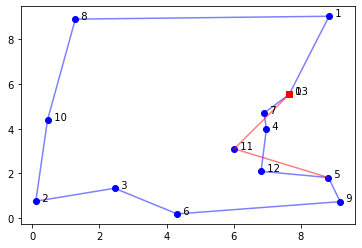

In [832]:
####drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#Plotting the n nodes without the node 0 (depot) and chose the color blue for each node.
plt.scatter(loc_x[1:],loc_y[1:],c='b')
for i in N:
    #plt.annotate('$ % d = % d $' %(i, q[i]),(loc_x[i],loc_y[i]))
    plt.annotate(' % d' %(i),(loc_x[i],loc_y[i]))
for i,j in active_arcs3:
    plt.plot([loc_x[i],loc_x[j]], [loc_y[i],loc_y[j]], c='b',alpha = 0.5)
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
#plt.axis('equal');

for i,j in active_arcs4:
    plt.plot([loc_x[i],loc_x[j]], [loc_y[i],loc_y[j]], c='r',alpha = 0.5)
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
#plt.axis('equal');

In [833]:
MyReg2

defaultdict(list,
            {3: [0, 1, 4, 5, 7, 9, 12, 13], 1: [2, 3, 8, 10], 2: [6, 11]})

In [834]:
z1[0,4]+z1[4,3]

22.607999999999997